In [1]:
import matplotlib.pyplot as plt
import numpy as np

from visualize_helpers import latexify, plot_fi_comparison_labeled

latexify()
FORMAT = "pdf"
continuous_cmaps = [
    "Blues",
    "Greens",
    "Reds",
    "Purples",
    "Oranges",
    "pink",
    "viridis",
    "plasma",
    "cividis",
    "magma",
    "inferno",
    "turbo",
    "bone",
    "gray",
    "copper",
]

In [2]:
%matplotlib inline

In [3]:
coords = np.load("coordinates.npy")
p_range = -coords[0, :, 6]
x_range = coords[:, 0, 2]

runs = {i: (f"fi_ms_{i}.npy", f"fi_ms_inv_{i}_with_remainder.npy") for i in [-1, 3, 6]}
data = {lbl: (np.load(fi_f), np.load(inv_f)) for lbl, (fi_f, inv_f) in runs.items()}

for lbl, (fi, inv) in data.items():
    print(  # noqa: T201
        f"{lbl}: FI {fi.shape} (channels={fi.shape[2]}, "
        f"remainder=last), inv {inv.shape}"
    )

-1: FI (50, 50, 5, 2, 2) (channels=5, remainder=last), inv (50, 50, 2, 2)
3: FI (50, 50, 10, 2, 2) (channels=10, remainder=last), inv (50, 50, 2, 2)
6: FI (50, 50, 37, 2, 2) (channels=37, remainder=last), inv (50, 50, 2, 2)


## Numerical sanity (read the booleans before trusting the plots)

In [4]:
def decompose(fi, a, b):  # noqa: ANN001, ANN201
    """Complete / resolved-only / remainder for FI matrix element (a, b)."""
    complete = np.sum(fi, axis=2)[:, :, a, b]
    resolved = np.sum(fi[:, :, :-1], axis=2)[:, :, a, b]
    remainder = fi[:, :, -1, a, b]
    return complete, resolved, remainder


for lbl, (fi, _) in data.items():
    for name, a, b in [("dx-dx", 0, 0), ("dz-dz", 1, 1)]:
        c, r, rem = decompose(fi, a, b)
        frac = np.nanmax(np.abs(rem) / np.where(c != 0, c, np.nan))
        print(  # noqa: T201
            f"{lbl} {name}: "
            f"complete>=resolved={np.all(c - r >= -1e-9)!s:5s} "
            f"remainder>=0={np.all(rem >= -1e-9)!s:5s} "
            f"max(remainder/complete)={frac:.2f}"
        )

-1 dx-dx: complete>=resolved=True  remainder>=0=True  max(remainder/complete)=0.72
-1 dz-dz: complete>=resolved=True  remainder>=0=True  max(remainder/complete)=0.91
3 dx-dx: complete>=resolved=True  remainder>=0=True  max(remainder/complete)=0.72
3 dz-dz: complete>=resolved=True  remainder>=0=True  max(remainder/complete)=0.88
6 dx-dx: complete>=resolved=True  remainder>=0=True  max(remainder/complete)=0.55
6 dz-dz: complete>=resolved=True  remainder>=0=True  max(remainder/complete)=0.74


## Decomposition per run — transverse $H_{\delta x \delta x}$

Each curve family is light->dark over $\delta z$. Expect **complete (green) on top**,
**resolved (blue) below it**, and the **remainder (orange) = the gap**, growing with
$\delta x$ as light leaks past the small mode bank.

In [5]:
fis_comb = []
fis_wo_rem = []
fis_rem = []
labels = []
for lbl, (fi, _) in data.items():
    c, r, rem = decompose(fi, 0, 0)
    fis_comb.append(c)
    fis_wo_rem.append(r)
    fis_rem.append(rem)
    name = "Dominant" if lbl == -1 else r"Order$\leq$" + f"{lbl - 1}"
    labels.append(name)

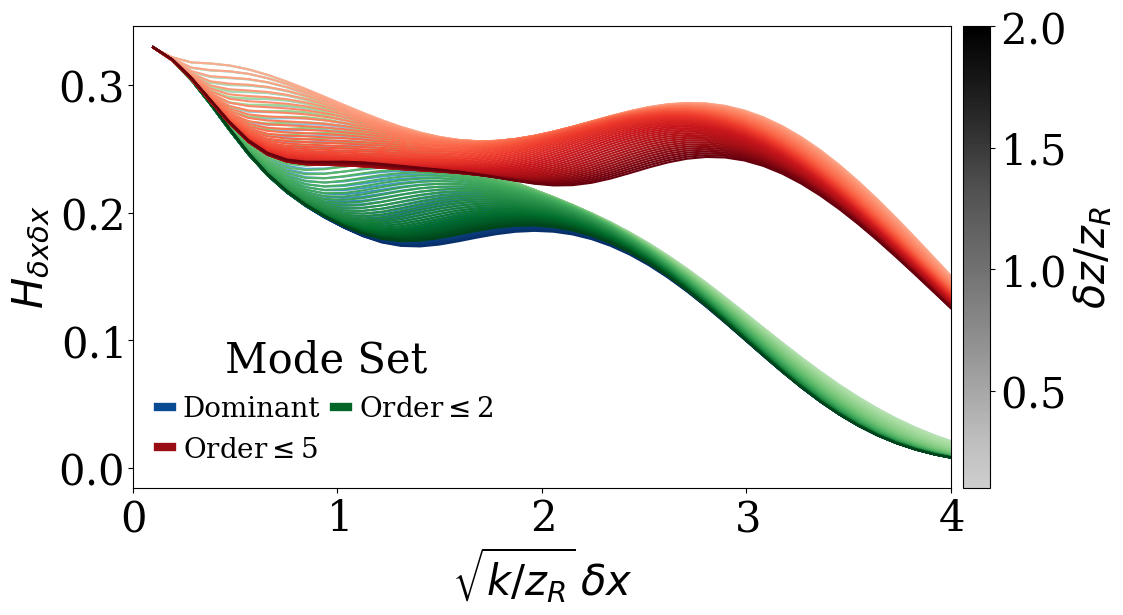

In [6]:
plot_fi_comparison_labeled(
    fis_comb,
    x_range,
    p_range,
    labels,
    cmaps=continuous_cmaps[: len(fis_comb)],
    xlabel=r"$\sqrt{k/z_R}\,\delta x$",
    ylabel=r"$H_{\delta x \delta x}$",
    gradient_label=r"$\delta z / z_R$",
    xlim=(0, 4),
    legend_title="Mode Set",
)
plt.show()

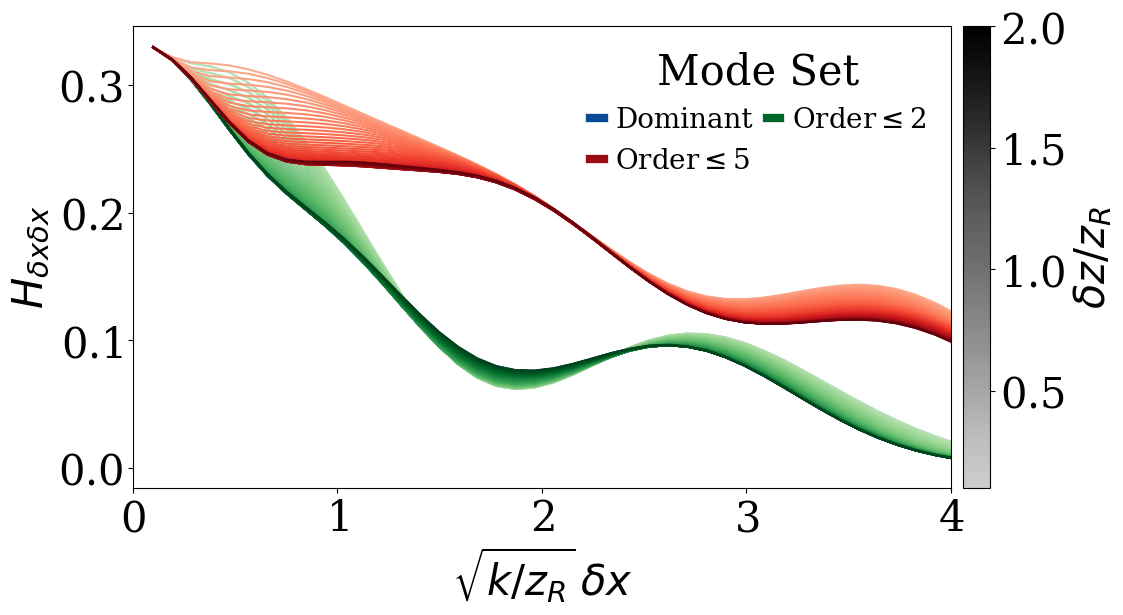

In [7]:
plot_fi_comparison_labeled(
    fis_wo_rem,
    x_range,
    p_range,
    labels,
    cmaps=continuous_cmaps[: len(fis_wo_rem)],
    xlabel=r"$\sqrt{k/z_R}\,\delta x$",
    ylabel=r"$H_{\delta x \delta x}$",
    gradient_label=r"$\delta z / z_R$",
    xlim=(0, 4),
    legend_title="Mode Set",
)
plt.show()

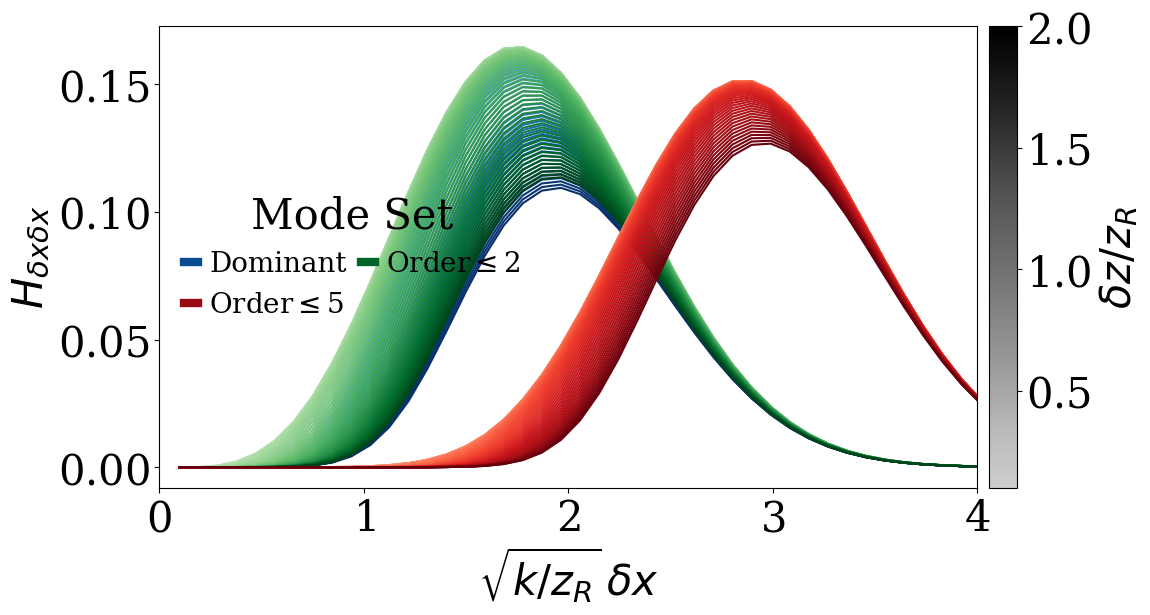

In [8]:
plot_fi_comparison_labeled(
    fis_rem,
    x_range,
    p_range,
    labels,
    cmaps=continuous_cmaps[: len(fis_rem)],
    xlabel=r"$\sqrt{k/z_R}\,\delta x$",
    ylabel=r"$H_{\delta x \delta x}$",
    gradient_label=r"$\delta z / z_R$",
    xlim=(0, 4),
    legend_title="Mode Set",
)
plt.show()

In [9]:
fis_inv_comb = []
labels = []
for lbl, (_, inv) in data.items():
    fis_inv_comb.append(inv[:, :, 0, 0])
    name = "Dominant" if lbl == -1 else f"Order {lbl - 1}"
    labels.append(name)

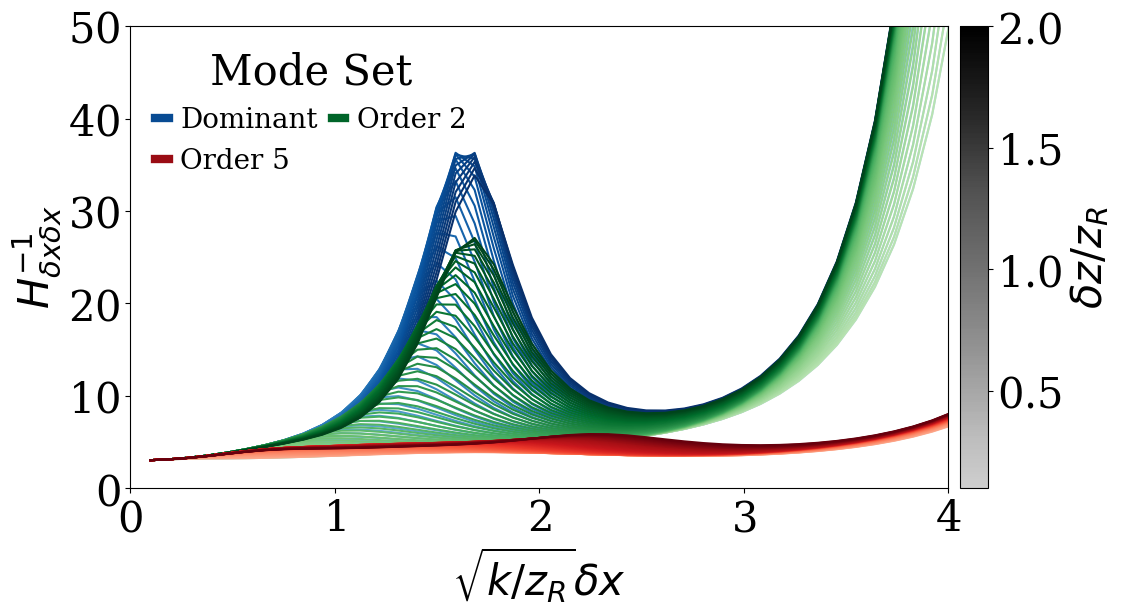

In [10]:
plot_fi_comparison_labeled(
    fis_inv_comb,
    x_range,
    p_range,
    labels,
    cmaps=continuous_cmaps[: len(fis_rem)],
    xlabel=r"$\sqrt{k/z_R} \delta x$",
    ylabel=r"$H^{-1}_{\delta x \delta x}$",
    gradient_label=r"$\delta z / z_R$",
    xlim=(0, 4),
    ylim=(0, 50),
    legend_title="Mode Set",
)
plt.show()

## Decomposition per run — axial $H_{\delta z \delta z}$

In [11]:
fis_comb = []
fis_wo_rem = []
fis_rem = []
labels = []
for lbl, (fi, _) in data.items():
    c, r, rem = decompose(fi, 1, 1)
    fis_comb.append(np.transpose(c))
    fis_wo_rem.append(np.transpose(r))
    fis_rem.append(np.transpose(rem))
    name = "Dominant" if lbl == -1 else f"Order {lbl - 1}"
    labels.append(name)

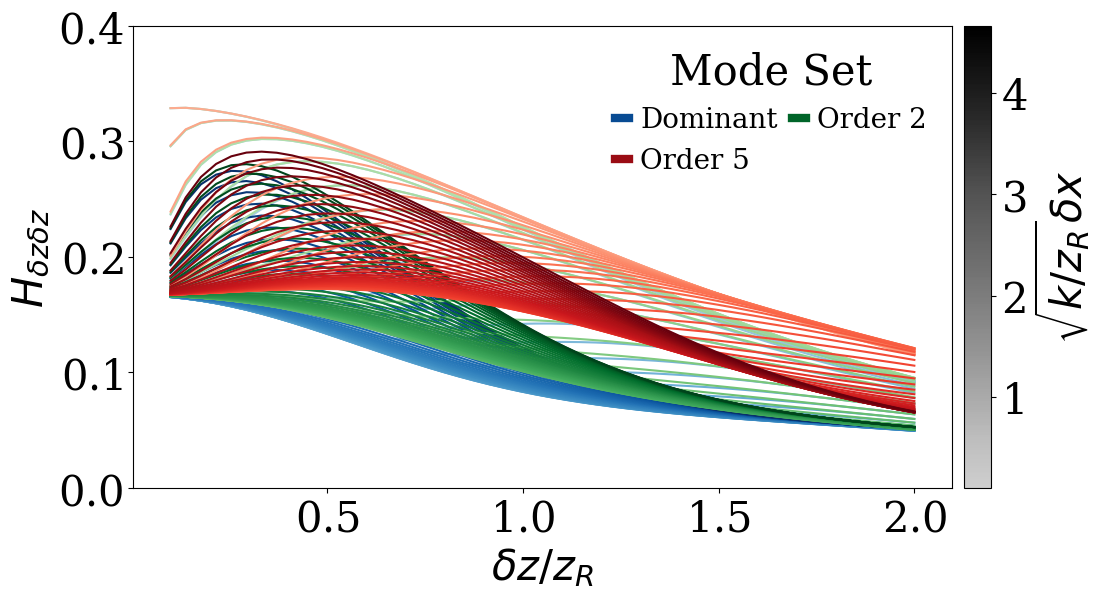

In [12]:
plot_fi_comparison_labeled(
    fis_comb,
    p_range,
    x_range,
    labels,
    cmaps=continuous_cmaps[: len(fis_comb)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R} \delta x$",
    ylim=(0, 0.4),
    legend_title="Mode Set",
)
plt.show()

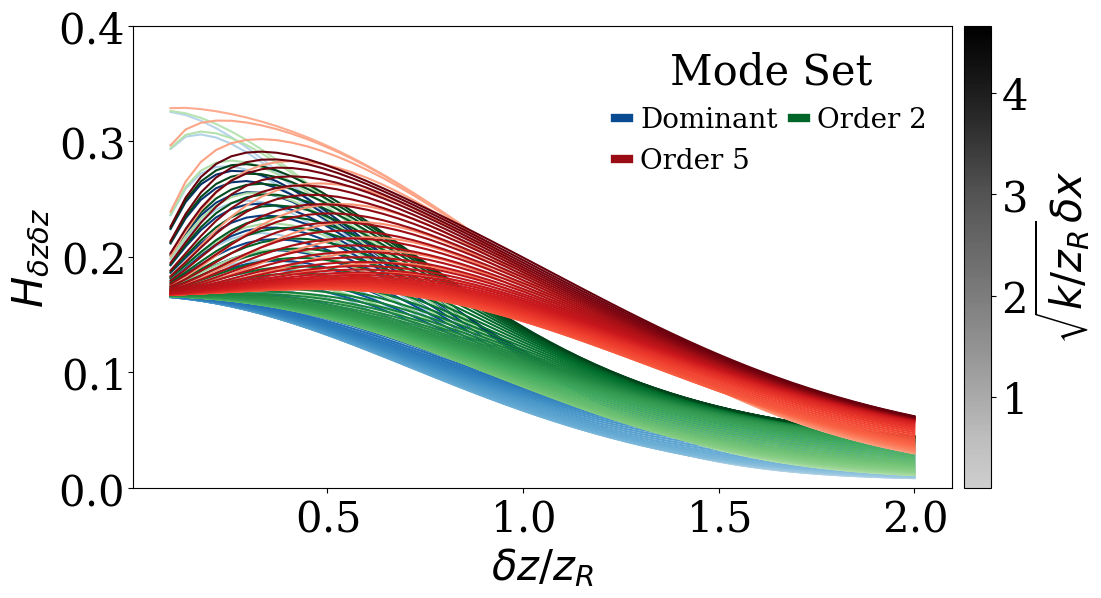

In [13]:
plot_fi_comparison_labeled(
    fis_wo_rem,
    p_range,
    x_range,
    labels,
    cmaps=continuous_cmaps[: len(fis_wo_rem)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R} \delta x$",
    ylim=(0, 0.4),
    legend_title="Mode Set",
)
plt.show()

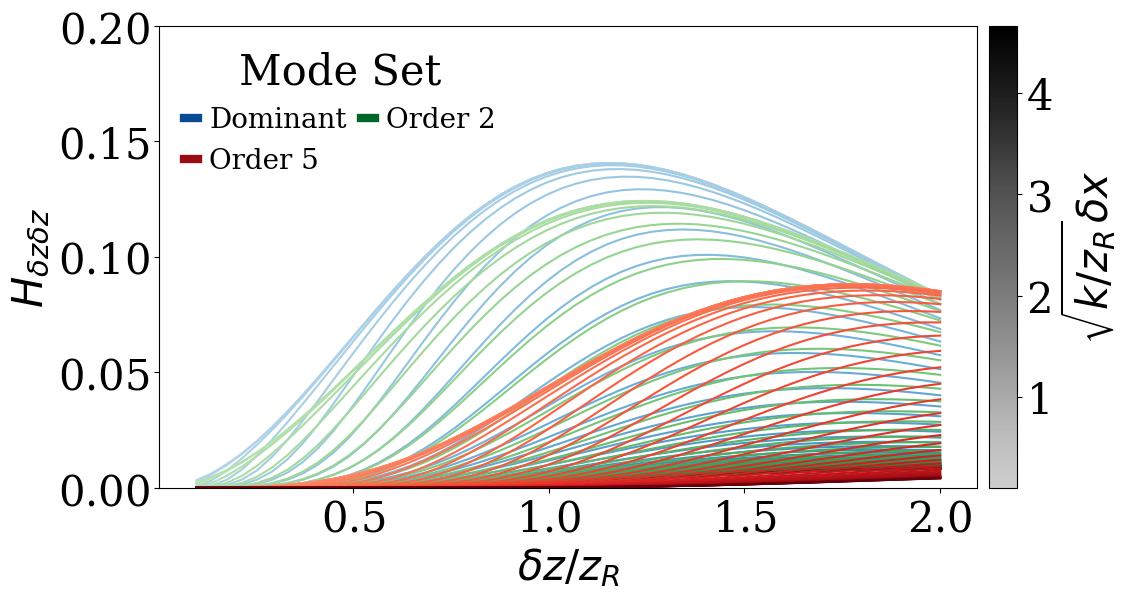

In [14]:
plot_fi_comparison_labeled(
    fis_rem,
    p_range,
    x_range,
    labels,
    cmaps=continuous_cmaps[: len(fis_rem)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R} \delta x$",
    ylim=(0, 0.2),
    legend_title="Mode Set",
)
plt.show()

In [15]:
fis_inv_comb = []
labels = []
for lbl, (_, inv) in data.items():
    fis_inv_comb.append(np.transpose(inv[:, :, 1, 1]))
    name = "Dominant" if lbl == -1 else f"Order {lbl - 1}"
    labels.append(name)

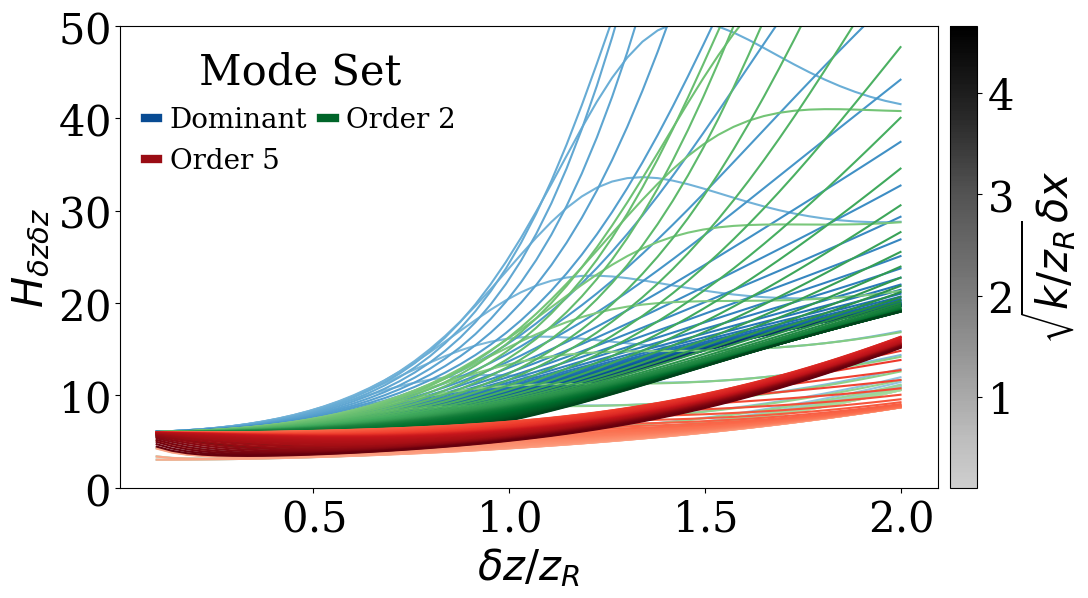

In [16]:
plot_fi_comparison_labeled(
    fis_inv_comb,
    p_range,
    x_range,
    labels,
    cmaps=continuous_cmaps[: len(fis_inv_comb)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R} \delta x$",
    ylim=(0, 50),
    legend_title="Mode Set",
)
plt.show()

## Spec 1 — leaked photon fraction and appendix figure export

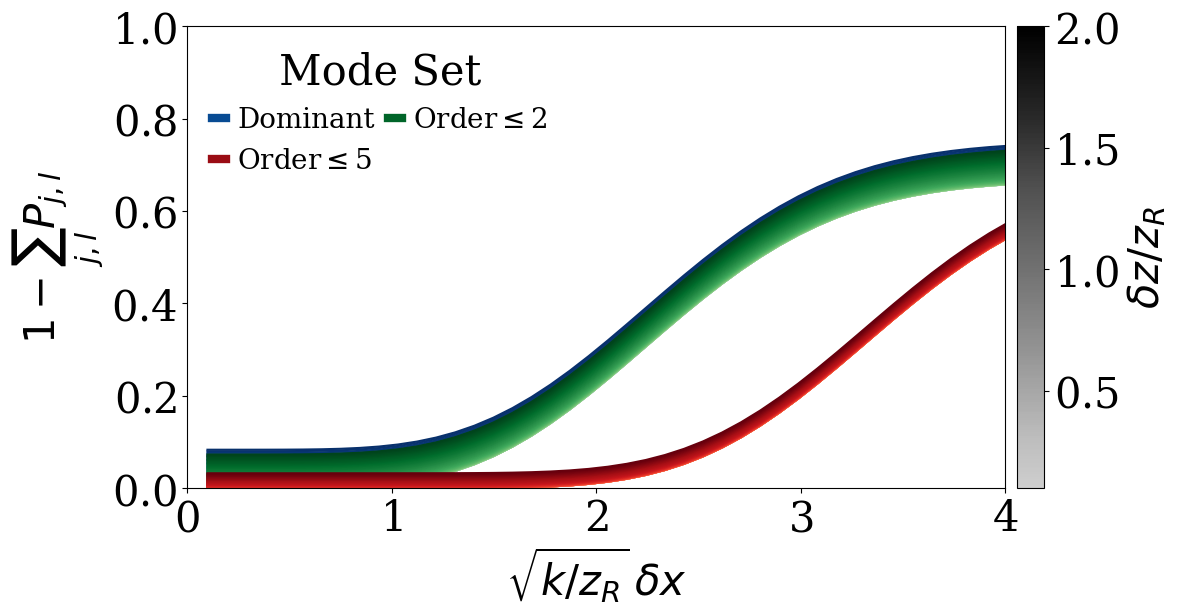

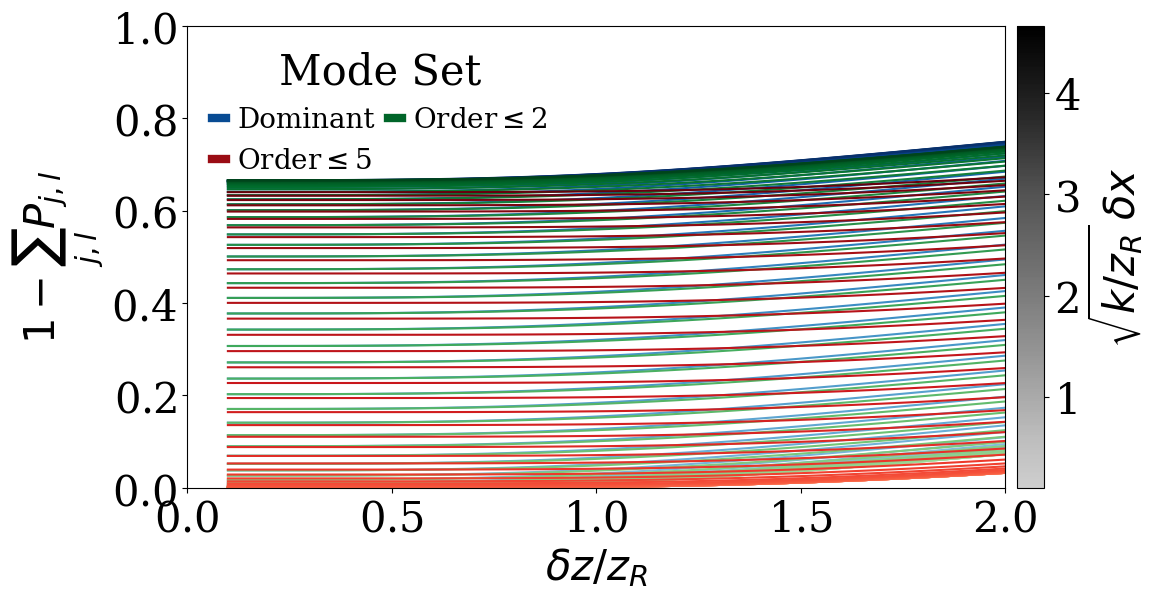

In [17]:
# Spec 1: leaked photon fraction L = 1 - sum_{(j,l) in M} P_{j,l}
leaked = {i: np.load(f"leaked_fraction_{i}.npy") for i in [-1, 3, 6]}
mode_labels = [
    "Dominant" if i == -1 else r"Order$\leq$" + f"{i - 1}" for i in [-1, 3, 6]
]

# width view: L vs delta x, gradient over delta z
fig, _ = plot_fi_comparison_labeled(
    [leaked[i] for i in [-1, 3, 6]],
    x_range,
    p_range,
    mode_labels,
    cmaps=continuous_cmaps[:3],
    xlabel=r"$\sqrt{k/z_R}\,\delta x$",
    ylabel=r"$1 - \sum_{j,l} P_{j,l}$",
    gradient_label=r"$\delta z / z_R$",
    xlim=(0, 4),
    ylim=(0, 1),
    legend_title="Mode Set",
)
fig.savefig("leaked_fraction_width.pdf", bbox_inches="tight")
plt.show()

# depth view: L vs delta z, gradient over delta x
fig, _ = plot_fi_comparison_labeled(
    [np.transpose(leaked[i]) for i in [-1, 3, 6]],
    p_range,
    x_range,
    mode_labels,
    cmaps=continuous_cmaps[:3],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$1 - \sum_{j,l} P_{j,l}$",
    gradient_label=r"$\sqrt{k/z_R}\,\delta x$",
    xlim=(0, 2),
    ylim=(0, 1),
    legend_title="Mode Set",
)
fig.savefig("leaked_fraction_depth.pdf", bbox_inches="tight")
plt.show()

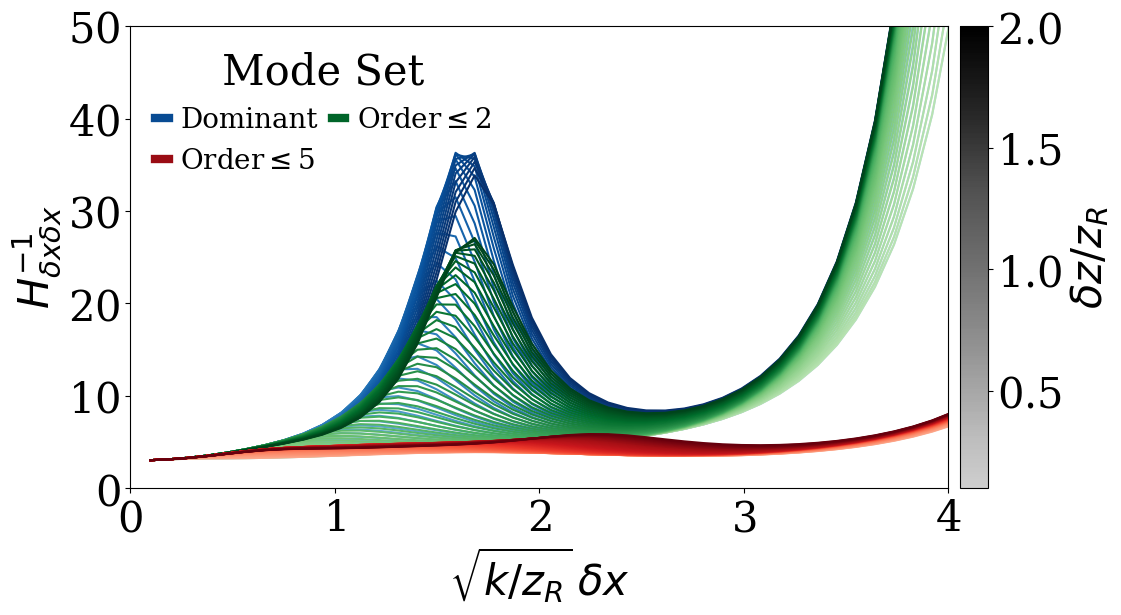

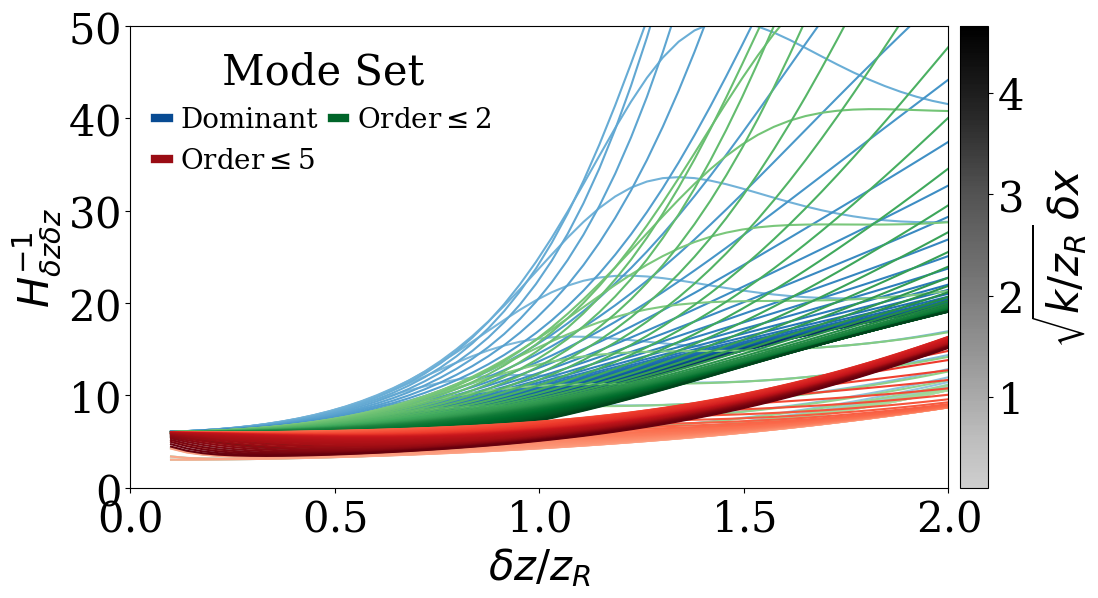

In [18]:
# Convergence of the CRB to the quantum limit as the bank is enlarged (with remainder)
conv_labels = ["Dominant" if i == -1 else r"Order$\leq$" + f"{i - 1}" for i in data]

fig, _ = plot_fi_comparison_labeled(
    [inv[:, :, 0, 0] for (_, inv) in data.values()],
    x_range,
    p_range,
    conv_labels,
    cmaps=continuous_cmaps[: len(data)],
    xlabel=r"$\sqrt{k/z_R}\,\delta x$",
    ylabel=r"$H^{-1}_{\delta x \delta x}$",
    gradient_label=r"$\delta z / z_R$",
    xlim=(0, 4),
    ylim=(0, 50),
    legend_title="Mode Set",
)
fig.savefig("crb_convergence_width.pdf", bbox_inches="tight")
plt.show()

fig, _ = plot_fi_comparison_labeled(
    [np.transpose(inv[:, :, 1, 1]) for (_, inv) in data.values()],
    p_range,
    x_range,
    conv_labels,
    cmaps=continuous_cmaps[: len(data)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H^{-1}_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R}\,\delta x$",
    xlim=(0, 2),
    ylim=(0, 50),
    legend_title="Mode Set",
)
fig.savefig("crb_convergence_depth.pdf", bbox_inches="tight")
plt.show()

## Leaked-fraction heatmap (alternative to curve view)

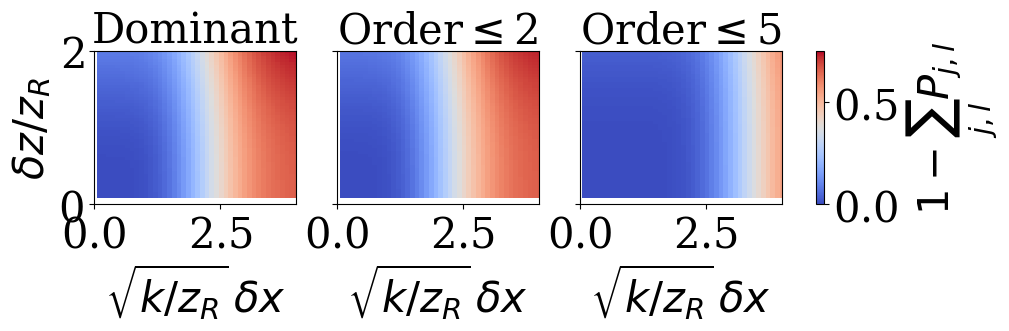

In [21]:
# Heatmap view of leaked fraction L = 1 - sum P_{j,l} over (delta x, delta z)
sets = [-1, 3, 6]
titles = ["Dominant", r"Order$\leq$2", r"Order$\leq$5"]
lf = {i: np.load(f"leaked_fraction_{i}.npy") for i in sets}
vmax = max(float(lf[i].max()) for i in sets)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), constrained_layout=True, sharey=True)
for ax, i, t in zip(axes, sets, titles):
    pcm = ax.pcolormesh(
        x_range, p_range, lf[i].T, vmin=0, vmax=vmax, shading="auto", cmap="coolwarm"
    )
    ax.set_title(t)
    ax.set_xlabel(r"$\sqrt{k/z_R}\,\delta x$")
    ax.set_xlim(0, 4)
    ax.set_ylim(0, 2)
axes[0].set_ylabel(r"$\delta z / z_R$")
fig.colorbar(pcm, ax=axes, label=r"$1 - \sum_{j,l} P_{j,l}$")
fig.savefig("leaked_fraction_heatmap.pdf", bbox_inches="tight")
plt.show()